## Desafío - Inferencia e hipótesis

In [236]:
import pandas as pd
import numpy as np
import random
from scipy import stats
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [172]:
df=pd.read_csv('earnings.csv')
df.head()

,height,weight,male,earn,earnk,ethnicity,education,mother_education,father_education,walk,exercise,smokenow,tense,angry,age
0,74,210.0,1,50000.0,50.0,White,16.0,16.0,16.0,3,3,2.0,0.0,0.0,45
1,66,125.0,0,60000.0,60.0,White,16.0,16.0,16.0,6,5,1.0,0.0,0.0,58
2,64,126.0,0,30000.0,30.0,White,16.0,16.0,16.0,8,1,2.0,1.0,1.0,29
3,65,200.0,0,25000.0,25.0,White,17.0,17.0,NaN,8,1,2.0,0.0,0.0,57
4,63,110.0,0,50000.0,50.0,Other,16.0,16.0,16.0,5,6,2.0,0.0,0.0,91


In [173]:
df.dtypes

height                int64
weight              float64
male                  int64
earn                float64
earnk               float64
ethnicity               str
education           float64
mother_education    float64
father_education    float64
walk                  int64
exercise              int64
smokenow            float64
tense               float64
angry               float64
age                   int64
dtype: object

In [174]:
df[['earn','height','age','male']].isna().sum()

earn      0
height    0
age       0
male      0
dtype: int64

In [175]:
df.duplicated().sum()

np.int64(0)

In [176]:
df.describe()

,height,weight,male,earn,earnk,education,mother_education,father_education,walk,exercise,smokenow,tense,angry,age
count,1816.000000,1789.000000,1816.000000,1816.000000,1816.000000,1814.000000,1572.000000,1521.000000,1816.000000,1816.000000,1815.000000,1815.000000,1815.000000,1816.000000
mean,66.568833,156.305198,0.371696,21147.296256,21.147296,13.235391,13.608779,13.652202,5.303414,3.049009,1.745455,1.421488,1.421488,42.934471
std,3.831822,34.617059,0.483391,22531.765123,22.531765,2.556638,3.219372,3.250811,2.601104,2.316385,0.435725,2.157850,2.157850,17.161672
min,57.000000,80.000000,0.000000,0.000000,0.000000,2.000000,3.000000,3.000000,1.000000,1.000000,1.000000,0.000000,0.000000,18.000000
25%,64.000000,130.000000,0.000000,6000.000000,6.000000,12.000000,12.000000,12.000000,3.000000,1.000000,1.000000,0.000000,0.000000,29.000000
50%,66.000000,150.000000,0.000000,16000.000000,16.000000,12.000000,13.000000,13.000000,6.000000,2.000000,2.000000,0.000000,0.000000,39.000000
75%,69.250000,180.000000,1.000000,27000.000000,27.000000,15.000000,16.000000,16.000000,8.000000,5.000000,2.000000,2.000000,2.000000,56.000000
max,82.000000,342.000000,1.000000,400000.000000,400.000000,18.000000,99.000000,99.000000,8.000000,7.000000,2.000000,7.000000,7.000000,91.000000


Suponiendo que el dataset es la población completa

In [ ]:
# 1.a Realiza 12 pruebas (4 por cada variable) con muestras de tamaño n = 25, en
# cada caso, con niveles de significancia diferentes pero inferiores a 0,1, para
# confirmar o rechazar las siguientes hipótesis considerando las alternativas.
# Crea para ello una fórmula que reciba los parámetros adecuados y responda
# "con nivel de confianza del ...%, se acepta la hipótesis nula/alternativa".

In [ ]:
def prueba_hip_media(variable,mu,tipo):
  datos=df[variable]
  alpha= round(np.random.uniform(0.01,0.1),2) # Se define el rango del alpha
  confianza=100*(1-alpha)
  muestra=np.random.choice(datos,25) # Se crea la muestra de 25 datos
  t_stat, p_value =  stats.ttest_1samp(muestra, mu, alternative = tipo)

  if p_value < alpha:
    if tipo == 'two-sided':
      print(f"Con nivel de confianza de {confianza}% se rechaza Ho y se acepta la hipótesis alternativa (la media es distinta {mu})")
    elif tipo == "greater":
      print(f"Con nivel de confianza de {confianza}% se rechaza Ho y se acepta la hipótesis alternativa (la media es mayor que {mu})")
    elif tipo == "less":
      print(f"Con nivel de confianza de {confianza}% se rechaza Ho y se acepta la hipótesis alternativa (la media es menor que {mu})")
  else:
    print(f"Con nivel de confianza de {confianza}% se acepta la hipótesis nula (no hay suficiente evidencia para rechazarla) (la media es igual a {mu})")
  print(f"Valor t: {round(t_stat,8)}, Valor p:  {round(p_value,8)} \n ")

In [179]:
casos = {
    'earn': [[20000, 'two-sided'], [35000, 'two-sided'], [25000, 'greater'], [32000, 'less']],
    'height': [[55, 'two-sided'], [68, 'two-sided'], [63, 'greater'], [70, 'less']],
    'age': [[44, 'two-sided'], [56, 'two-sided'], [51   , 'greater'], [62, 'less']]}

In [180]:
for key, value in casos.items():
    print(f"Variable: {key}  /////////////////////////////////////////////")
    for configuracion in value:
        prueba_hip_media(key, configuracion[0], configuracion[1])

Variable: earn  /////////////////////////////////////////////
Con nivel de confianza de 96.0% se acepta la hipótesis nula (no hay suficiente evidencia para rechazarla) (la media es igual a 20000)
Valor t: 0.74016786, Valor p:  0.46637778 
 
Con nivel de confianza de 97.0% se rechaza Ho y se acepta la hipótesis alternativa (la media es distinta 35000)
Valor t: -6.174436, Valor p:  2.22e-06 
 
Con nivel de confianza de 93.0% se acepta la hipótesis nula (no hay suficiente evidencia para rechazarla) (la media es igual a 25000)
Valor t: -1.18384811, Valor p:  0.87596681 
 
Con nivel de confianza de 93.0% se rechaza Ho y se acepta la hipótesis alternativa (la media es menor que 32000)
Valor t: -3.22547326, Valor p:  0.00180538 
 
Variable: height  /////////////////////////////////////////////
Con nivel de confianza de 95.0% se rechaza Ho y se acepta la hipótesis alternativa (la media es distinta 55)
Valor t: 15.51269801, Valor p:  0.0 
 
Con nivel de confianza de 94.0% se rechaza Ho y se ace

In [ ]:
# 1.b Calcula la media poblacional para cada variable. ¿Son correctos los
#  obtenidos por tus pruebas?

In [182]:
df[['earn','height','age']].mean()

earn      21147.296256
height       66.568833
age          42.934471
dtype: float64

In [183]:
"""
En el caso de las ganancias (earn), todas las conclusiones obtenidas parecen
coherentes al compararlas con la media poblacional, que es aproximadamente 21.150.

En el primer y tercer caso (H0: x = 20.000 y H0: x = 25.000, respectivamente)
no se encontró evidencia suficiente para rechazar la hipótesis nula. Esto resulta
razonable, ya que ambos valores son relativamente cercanos a la media poblacional.
Por otro lado, en el segundo y cuarto caso se rechazó H0 (x = 35.000 y x = 32.000,
respectivamente), lo cual también es consistente con la media poblacional observada,
considerablemente inferior a dichos valores.

Para la variable altura (height), cuya media poblacional es aproximadamente 66,6,
la mayoría de los resultados son coherentes con dicho valor. En particular, el
rechazo de H0: x = 55 y la evidencia a favor de que la media es mayor que 63 y
menor que 70 son resultados esperables dada la ubicación de la media poblacional.
Sin embargo, en el caso de H0: x = 68 se obtuvo evidencia suficiente para rechazar
la hipótesis nula, a pesar de que este valor es cercano a la media poblacional.
Este resultado puede explicarse por la variabilidad propia del muestreo aleatorio
y por el hecho de haber trabajado con una muestra relativamente pequeña (n = 25).

Finalmente, para la variable edad (age), cuya media poblacional es aproximadamente
42,93, la mayoría de los resultados obtenidos también son consistentes con el valor
poblacional. En el caso de H0: x = 51 no se obtuvo evidencia suficiente para
rechazar la hipótesis nula. Aunque 51 es superior a la media poblacional, la
diferencia observada en la muestra no fue lo suficientemente grande para superar
el nivel de exigencia impuesto por el nivel de significancia utilizado. El resto
de los resultados son coherentes con una media poblacional cercana a 42,93,
rechazándose aquellas hipótesis que proponen valores considerablemente distintos.
"""

'\nEn el caso de las ganancias (earn), todas las conclusiones obtenidas parecen\ncoherentes al compararlas con la media poblacional, que es aproximadamente 21.150.\n\nEn el primer y tercer caso (H0: x = 20.000 y H0: x = 25.000, respectivamente)\nno se encontró evidencia suficiente para rechazar la hipótesis nula. Esto resulta\nrazonable, ya que ambos valores son relativamente cercanos a la media poblacional.\nPor otro lado, en el segundo y cuarto caso se rechazó H0 (x = 35.000 y x = 32.000,\nrespectivamente), lo cual también es consistente con la media poblacional observada,\nconsiderablemente inferior a dichos valores.\n\nPara la variable altura (height), cuya media poblacional es aproximadamente 66,6,\nla mayoría de los resultados son coherentes con dicho valor. En particular, el\nrechazo de H0: x = 55 y la evidencia a favor de que la media es mayor que 63 y\nmenor que 70 son resultados esperables dada la ubicación de la media poblacional.\nSin embargo, en el caso de H0: x = 68 se ob

In [ ]:
# 2.Crea una función que estime la proporción de hombres en el dataset, considerando
# una muestra de 50 individuos, con niveles de confianza de 95% y 99%. Escribe con
# palabras tus resultados al ejecutar la función e interpreta. Compara con la proporción real.


In [ ]:
def intervalo_proporcion(variable, n, significancias):
    muestra = np.random.choice(variable, n)
    exitos =(muestra == 1).sum()
    resultados = []
    
    for alpha in significancias: 
        ic = sm.stats.proportion_confint(exitos, n, alpha)
        resultados.append(ic)
    return resultados

In [214]:
intervalo_proporcion(df['male'],50,[0.01,0.05])

[(0.16743866033962532, 0.5125613396603748),
 (0.2086970404473866, 0.4713029595526135)]

In [216]:
df['male'].mean() # Proporción poblacional de hombres (male == 1)

np.float64(0.3716960352422907)

In [ ]:
"""
Para una confianza de 99 y 95% (alpha: 0.01 y 0.05 respectivamente),para una muestra de 50 individuos,
se obtiene que para ambas estimaciones el intervalo de confianza contiene la proporción poblacional de
hombres de 37,2%, lo cual es esperable para el tamaño de la muestra. En el caso de que la muestra
fuera mas pequeña, se obtendrian intervalos mas imprecisos. En el caso de que la muestra sea mayor,
el intervalo seria mas pequeño, dejando poco margen de error para la estimación.
"""

In [ ]:
# 3. Considerando el dataset como una muestra, verifica si el género (male=1 significa
# ‘hombre”) influye sobre el sueldo “earn” de las personas. Explica y justifica tu
# procedimiento.


In [272]:
male_earn = df[df["male"] == 1]["earn"]
no_male_earn = df[df["male"] == 0]["earn"]

t_stat,p_value = stats.ttest_ind(male_earn,no_male_earn,equal_var=False)

In [273]:
# Nivel de significancia (alfa)
alpha = 0.01

# Comprobar si el valor p es menor que alfa para rechazar la hipótesis nula
if p_value < alpha:
    print("Resultado: Se rechaza la hipótesis nula, por lo que se acepta la h.alternativa")
else:
    print("Resultado: No se rechaza la hipótesis nula")

# Imprimir el valor t y el valor p
print(f"Valor t: {t_stat}")
print(f"Valor p: {p_value}")

Resultado: Se rechaza la hipótesis nula, por lo que se acepta la h.alternativa
Valor t: 11.86459381795286
Valor p: 2.7373648004575482e-30


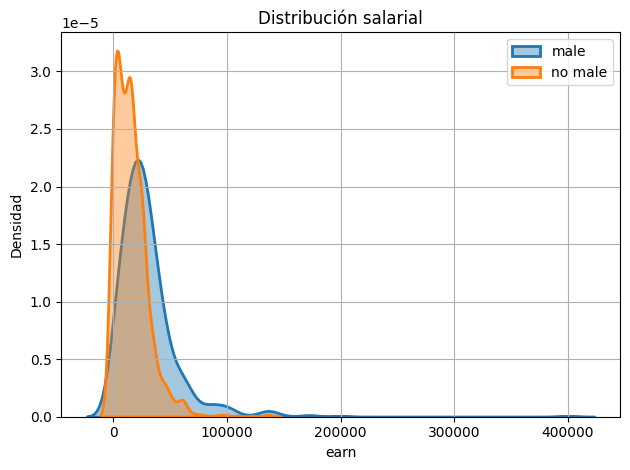

In [274]:
male_earn    = male_earn.astype(float)
no_male_earn  = no_male_earn.astype(float)
# Histograma con curva de densidad corregido
sns.kdeplot(x=male_earn, label="male", fill=True, alpha=0.4, linewidth=2)
sns.kdeplot(x=no_male_earn, label="no male", fill=True, alpha=0.4, linewidth=2)
plt.title("Distribución salarial")
plt.xlabel("earn")
plt.ylabel("Densidad")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

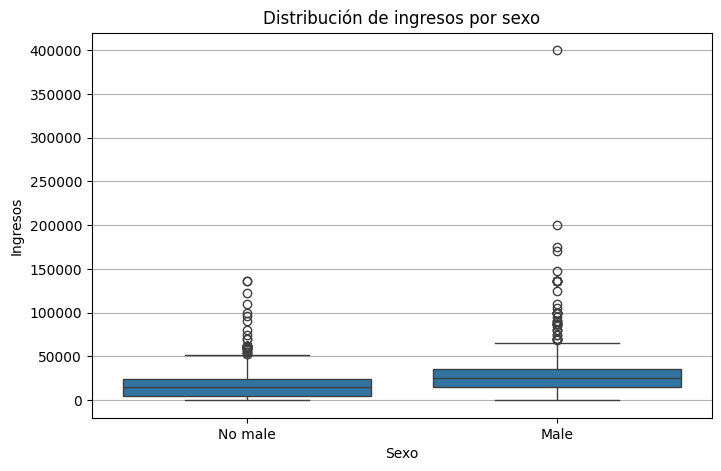

In [275]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="male", y="earn")
plt.title("Distribución de ingresos por sexo")
plt.xlabel("Sexo")
plt.ylabel("Ingresos")
plt.xticks([0,1], ["No male", "Male"])
plt.grid(axis="y")
plt.show()

In [ ]:
"""
H0: promedio_male_earn = promedio_no_male_earn
H1: promedio_male_earn != promedio_no_male_earn
Se plantea la hipótesis nula de que los promedios son iguales, independientes del genero,
pero esta se rechaza, aceptando con evidencia suficiente la h.alternativa que indica que 
los promedios de ingreso son distintos con una confianza del 99% (p<alpha=0.01).
Ademas, se observa una distribución de los ingresos para hombres mas a la derecha, es decir,
que los hombres tienen mayores ingresos en promedio y tambien tienen datos atipicos mas extremos.
Estos datos atipicos podrían distorcionan el promedio,a afectando de manera directa la
prueba de hipótesis.
"""

In [276]:
def filtrar_atipicos(columna):
    Q1 = columna.quantile(0.25)
    Q3 = columna.quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    condicion = (columna >= lim_inf) & (columna <= lim_sup)
    return condicion

In [277]:
condicion = filtrar_atipicos(df['earn'])

df_sin_atipicos = df[condicion]

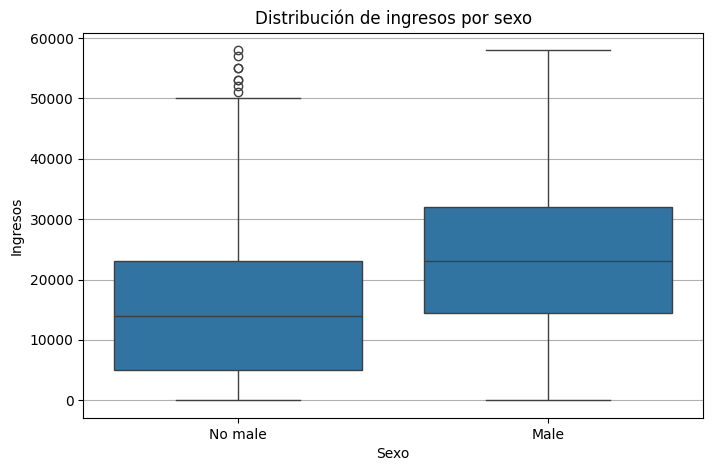

In [278]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df_sin_atipicos, x="male", y="earn")
plt.title("Distribución de ingresos por sexo")
plt.xlabel("Sexo")
plt.ylabel("Ingresos")
plt.xticks([0,1], ["No male", "Male"])
plt.grid(axis="y")
plt.show()

In [283]:
male_earn_2 = df_sin_atipicos[df_sin_atipicos["male"] == 1]["earn"]
no_male_earn_2 = df_sin_atipicos[df_sin_atipicos["male"] == 0]["earn"]
t_stat, p_value = stats.ttest_ind(male_earn_2, no_male_earn_2, equal_var=False)     
alpha = 0.01
if p_value < alpha:
    print("Se rechaza H0")
else:
    print("No se rechaza H0")

print(f"t = {t_stat:.4f}")
print(f"p = {p_value:.4f}")                       

Se rechaza H0
t = 13.3191
p = 0.0000


In [ ]:
"""
Dada la duda sembrada anteriormente, se tomo la decisión de eliminar datos atipicos.
Sin embargo el resultado no cambio, se rechaza la H0 nuevamente, 
aceptando la H1 con una confianza del 99%.
"""